Описание данных: две компонентны скорости (Vx, Vy), полученные из моделирования турбулентной струи в воде (несжимаемая среда). Снизу -- твердая стенка, сверху задается профиль вертикальной скорости в виде функции Гаусса. Справа и слева -- свободные границы.

Задание: необходимо прочитать данные двух компонент скорости из файлов. Выбрать 10 x 10 точек равномерно, и восстановить поля скоростей, включая в Loss-функцию отклонения от этих точек и невязку от уравнения непрерывности.

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import griddata

import torch
import torch.nn as nn
from torch.autograd import grad
from torch import optim

import zipfile

Загрузить в google collab zip-архив с данными. Распоковать данные.

In [6]:
!unzip PINN_data.zip

Archive:  PINN_data.zip
replace PINN_data/Vx.txt? [y]es, [n]o, [A]ll, [N]one, [r]ename: n
replace PINN_data/Vy.txt? [y]es, [n]o, [A]ll, [N]one, [r]ename: n


Написать функцию для чтения файлов.

Входные аргументы функции: название файла (string)

Выходные данные: массив из N строк и 3 столбцов (np.array)

In [7]:
def read_data(filename):
    data = np.loadtxt(filename)
    return data

Проверить, что функция возвращает правильные массивы.

Вывести размеры массива.

Построить точечный график с координатами точек.

Vx shape: (40210, 3)
Vy shape: (40210, 3)


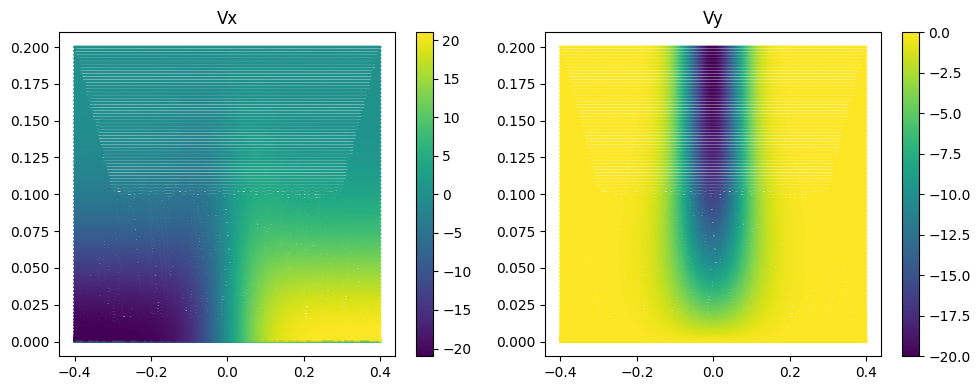

In [10]:
data_vx = read_data('PINN_data/Vx.txt')
data_vy = read_data('PINN_data/Vy.txt')

print('Vx shape:', data_vx.shape)
print('Vy shape:', data_vy.shape)

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.scatter(data_vx[:, 0], data_vx[:, 1], c=data_vx[:, 2], s=1)
plt.colorbar()
plt.title('Vx')
plt.subplot(1, 2, 2)
plt.scatter(data_vy[:, 0], data_vy[:, 1], c=data_vy[:, 2], s=1)
plt.colorbar()
plt.title('Vy')
plt.tight_layout()
plt.show()

Создать класс с двумя полями:
*   Vx
*   Vy

In [11]:
class VelocityData:
    def __init__(self, Vx, Vy):
        self.Vx = Vx
        self.Vy = Vy

In [12]:
vel = VelocityData(data_vx, data_vy)
print(vel.Vx.shape, vel.Vy.shape)

(40210, 3) (40210, 3)


Создать функцию, которая будет аппроксимировать исходные данные на равномерную сетку.

In [13]:
def to_uniform_grid(data, n=10):
    x = data[:, 0]
    y = data[:, 1]
    v = data[:, 2]
    xi = np.linspace(x.min(), x.max(), n)
    yi = np.linspace(y.min(), y.max(), n)
    Xi, Yi = np.meshgrid(xi, yi)
    Vi = griddata((x, y), v, (Xi, Yi), method='cubic')
    return Xi, Yi, Vi

In [14]:
Xi_vx, Yi_vx, Vi_vx = to_uniform_grid(vel.Vx, n=10)
Xi_vy, Yi_vy, Vi_vy = to_uniform_grid(vel.Vy, n=10)

print(Xi_vx.shape, Vi_vx.shape, Vi_vy.shape)

(10, 10) (10, 10) (10, 10)


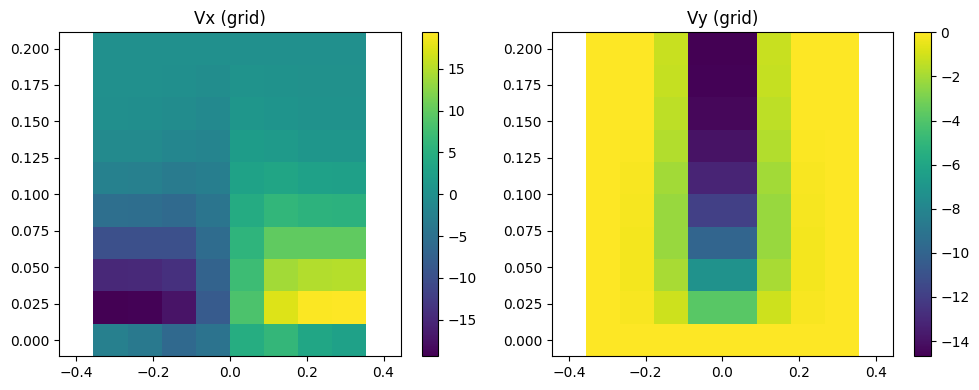

In [15]:
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.pcolormesh(Xi_vx, Yi_vx, Vi_vx, shading='auto')
plt.colorbar()
plt.title('Vx (grid)')
plt.subplot(1, 2, 2)
plt.pcolormesh(Xi_vy, Yi_vy, Vi_vy, shading='auto')
plt.colorbar()
plt.title('Vy (grid)')
plt.tight_layout()
plt.show()

Написать простую нейросеть, использовать шаблон как здесь:

https://docs.pytorch.org/tutorials/beginner/basics/buildmodel_tutorial.html

Но использовать nn.Tanh()

Проверить, что нейросеть задана правильно.

In [16]:
class PINN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(2, 32),
            nn.Tanh(),
            nn.Linear(32, 32),
            nn.Tanh(),
            nn.Linear(32, 32),
            nn.Tanh(),
            nn.Linear(32, 2)
        )

    def forward(self, x):
        return self.net(x)

In [17]:
model = PINN()
test_in = torch.randn(5, 2)
test_out = model(test_in)
print('Input shape:', test_in.shape)
print('Output shape:', test_out.shape)
print(model)

Input shape: torch.Size([5, 2])
Output shape: torch.Size([5, 2])
PINN(
  (net): Sequential(
    (0): Linear(in_features=2, out_features=32, bias=True)
    (1): Tanh()
    (2): Linear(in_features=32, out_features=32, bias=True)
    (3): Tanh()
    (4): Linear(in_features=32, out_features=32, bias=True)
    (5): Tanh()
    (6): Linear(in_features=32, out_features=2, bias=True)
  )
)


Написать Loss функцию

Написать цикл обучения

https://docs.pytorch.org/tutorials/beginner/introyt/trainingyt.html#the-training-loop